# 01 · Desk check of the products

**Question:** How good are the products we use, Hansen Global Forest Change for forest loss and Esri Land Use/Land Cover for land use, and their alternatives?

This builds on the stage-1 assessment (`../lulc_benchmark.ipynb`, report `docs/forest_loss_assessment.qmd`), which read 10 products at 56,712 points (one per H3 resolution-7 hexagon) and compared forest area and loss with the official figures. It adds four things the stage-1 assessment does not cover:

1. the accuracy each product's producers and independent studies report (section 2);
2. JRC TMF's **degradation** next to its deforestation, since the official reference level reports the two separately (section 3);
3. how stable Esri is from one year to the next for **all seven classes**, which the land-use forecast uses, not only forest (section 4);
4. one table of what each product can and cannot be used for (section 5).

Everything is computed from the point tables saved by the stage-1 notebook
(`../output_datasets/lulc_benchmark/`), except Dynamic World's annual maps in section 4 are saved in `output/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path.cwd().parent / "output_datasets" / "lulc_benchmark"      # saved by ../lulc_benchmark.ipynb
OUT = Path.cwd() / "output"
OUT.mkdir(exist_ok=True)

points = pd.read_parquet(DATA / "sample_points_h3res7.parquet").set_index("point_id")
weights = points["weight_km2"]
TOTAL_KM2 = weights.sum()
read = lambda key: pd.read_parquet(DATA / f"{key}_h3res7.parquet").set_index("point_id")


def area_km2(indicator):
    """Area of the points where `indicator` is True, and its standard error: each point stands for its
    hexagon (the sample-based estimate of Olofsson et al. 2014, as in the stage-1 notebook)."""
    x = indicator.reindex(weights.index).fillna(False).astype(float)
    share = np.average(x, weights=weights)
    return TOTAL_KM2 * share, TOTAL_KM2 * np.sqrt(share * (1 - share) / len(x))


print(f"{len(points):,} points, {TOTAL_KM2:,.0f} km²")

56,712 points, 245,320 km²


## 2 · What the producers and independent studies report

Accuracy of each product as published. These figures are global or continental. They are also accuracies of a map of one date; the accuracy of change between two dates is lower, because the errors of both maps add up (Pontius & Lippitt 2006; Olofsson et al. 2014).

They show what accuracy to expect and which alternatives are worth testing.
Accuracy can differ a lot from one region to another, so **the accuracy in Guinea is measured in tiers 2 and 3** (notebooks 02–04). Sections 3 and 4 below are not accuracies either: they compare totals with the official figures and check how stable each product is, which can show a product is implausible for Guinea but not how accurate it is.

| Product | Used for | Accuracy reported by its producers | Independent accuracy | Known weaknesses relevant to Guinea |
|---|---|---|---|---|
| **Hansen Global Forest Change** (UMD, 30 m) | Tree-cover loss per year | Loss: user's accuracy 87%, producer's 83% (global; Hansen et al. 2013, supplement) | Up to 48% of loss missed in sub-Saharan Africa, especially in dry forests; disturbances under 2 ha underestimated by up to 50% (as summarised by Masolele et al. 2024) | Counts canopy loss, not conversion: includes degradation, fire and fallow clearing; method changed in 2013 (stage 1) |
| **JRC Tropical Moist Forests** (30 m) | Deforestation and degradation, separately | Disturbances: 91.4% overall accuracy, 9.4% omission, 8.1% commission (12,235 plots); disturbed area underestimated by about 12% (Vancutsem et al. 2021) | – | Moist forest only: dry forest and savanna woodland are "other land" by design |
| **GLC_FCS30D** (30 m) | Annual land cover to 2022 | 80.9% overall, 10 basic classes (Zhang et al. 2024) | 79.5% and 81.9% against US and EU time series (Zhang et al. 2024) | Not updated since 2022 |
| **Esri Land Use/Land Cover** (10 m) | Annual land cover, used by the land-use forecast | About 85% overall (Karra et al. 2021) | 75% (Venter et al. 2022; not fully independent, Xu et al. 2024); 73.4%, the lowest of the three 10 m maps (Xu et al. 2024) | Each year classified on its own (section 4) |
| **Dynamic World** (10 m) | Land cover per image, any date | – | 72% (Venter et al. 2022); between WorldCover and Esri (Xu et al. 2024) | Annual maps must be composited; reading many years is costly (stage 1) |
| **ESA WorldCover** (10 m) | Land cover 2020 and 2021 | 74.4% (2020), 76.7% (2021) (ESA) | 83.8%, the highest of the three 10 m maps (Xu et al. 2024) | Two dates, different algorithms: no annual change |
| **JRC Global Forest Cover 2020** (10 m) | Forest in 2020 (EU deforestation regulation baseline) | – | 91.6% overall, 4,730 points (IIASA, reported by WRI) | One date |

For maps of one date, WorldCover is the most accurate 10 m map in the most recent independent validation, and Esri the least. For change, only Hansen and TMF were validated as change products, and TMF only for moist forest.

## 3 · Forest loss against the official figures

Guinea's reference level (NERF 2026) reports **deforestation** (forest to non-forest, 637 km² a
year on average over 2016–2024) and **degradation** (dense to open forest, about 1,950 km² a year)
separately, from 1,688 plots interpreted with the national definition. Hansen counts any canopy
loss; TMF separates deforestation from degradation, but only in moist forest.

TMF classes in its annual change product: 1 undisturbed, 2 degraded, 3 deforested, 4 regrowing
moist forest, 5 water, 6 other land. A year's deforestation is a point going from 1, 2 or 4 to 3;
its degradation, a point going from 1 to 2.

In [2]:
NERF_DEFORESTATION_HA = {2016: 99_057.23, 2017: 22_908.00, 2018: 104_242.07, 2019: 64_695.23, 2020: 22_908.00,
                         2021: 30_333.22, 2022: 62_454.85, 2023: 125_361.67, 2024: 41_787.22}   # NERF 2026, Tableau 8
NERF_DEGRADATION_KM2 = 1_950        # NERF 2026, mean annual degradation 2016-2024 (approximate)
YEARS = list(NERF_DEFORESTATION_HA)

tmf, hansen = read("tmf"), read("hansen")
mean_area = lambda masks: np.mean([area_km2(m)[0] for m in masks])
loss = {
    "Hansen, canopy > 10 % (legal threshold)": mean_area([(hansen.treecover2000 > 10) & (hansen.lossyear == y - 2000) for y in YEARS]),
    "Hansen, canopy > 30 %": mean_area([(hansen.treecover2000 > 30) & (hansen.lossyear == y - 2000) for y in YEARS]),
    "JRC TMF, deforestation": mean_area([tmf[str(y - 1)].isin([1, 2, 4]) & (tmf[str(y)] == 3) for y in YEARS]),
    "JRC TMF, degradation": mean_area([(tmf[str(y - 1)] == 1) & (tmf[str(y)] == 2) for y in YEARS]),
}
loss["JRC TMF, deforestation + degradation"] = loss["JRC TMF, deforestation"] + loss["JRC TMF, degradation"]
official_def = np.mean(list(NERF_DEFORESTATION_HA.values())) / 100
table = pd.DataFrame({"km² per year, 2016–2024": loss})
table["× NERF deforestation"] = table.iloc[:, 0] / official_def
table["× NERF deforestation + degradation"] = table.iloc[:, 0] / (official_def + NERF_DEGRADATION_KM2)
moist = area_km2(tmf["2016"].isin([1, 2, 4]))[0]
print(f"NERF: deforestation {official_def:,.0f} km²/yr, degradation about {NERF_DEGRADATION_KM2:,} km²/yr. "
      f"TMF moist forest in 2016: {moist:,.0f} km² ({100 * moist / TOTAL_KM2:.1f} % of Guinea).")
table.round(2).to_csv(OUT / "01_loss_vs_nerf.csv")
table.round(2)

NERF: deforestation 637 km²/yr, degradation about 1,950 km²/yr. TMF moist forest in 2016: 8,390 km² (3.4 % of Guinea).


,"km² per year, 2016–2024",× NERF deforestation,× NERF deforestation + degradation
"Hansen, canopy > 10 % (legal threshold)",2846.62,4.47,1.10
"Hansen, canopy > 30 %",1769.97,2.78,0.68
"JRC TMF, deforestation",117.77,0.18,0.05
"JRC TMF, degradation",80.53,0.13,0.03
"JRC TMF, deforestation + degradation",198.29,0.31,0.08


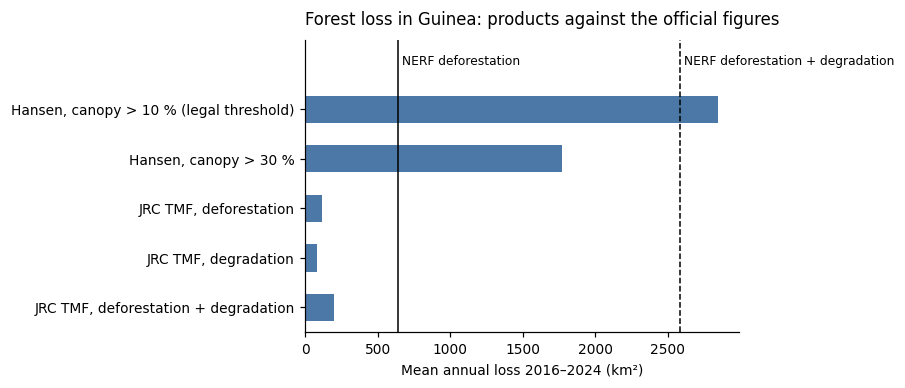

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(loss)[::-1]
ax.barh(names, [loss[n] for n in names], color="#4c78a8", height=0.55)
for value, label, style in ((official_def, "NERF deforestation", "-"),
                            (official_def + NERF_DEGRADATION_KM2, "NERF deforestation + degradation", "--")):
    ax.axvline(value, color="black", linestyle=style, linewidth=1)
    ax.text(value, len(names) - 0.15, f" {label}", fontsize=8, va="bottom")
ax.set_ylim(-0.5, len(names) + 0.4)
ax.set_xlabel("Mean annual loss 2016–2024 (km²)")
ax.set_title("Forest loss in Guinea: products against the official figures", loc="left", pad=10)
plt.tight_layout(); plt.show()

**Reading:**

* **Hansen's loss is the size of NERF's deforestation plus degradation (about 2,590 km² a year),
  not of its deforestation alone** (637 km²). At the legal 10 % threshold Hansen gives 2,847 km² a
  year (× 1.1 of deforestation plus degradation, × 4.5 of deforestation); at 30 %, 1,770 km² (× 0.7
  and × 2.8). So Hansen's loss should be reported as tree-cover loss, not as deforestation.
* **TMF sees only a small part of the country.** Its moist forest covers about 8,400 km² (3.4 % of
  Guinea), so its deforestation (118 km² a year) and degradation (81 km² a year) are far below the
  national figures. It can check the south-east's moist forest, not the national total.
* Neither product's yearly values should be compared with NERF year by year: NERF's 95 %
  confidence intervals are 56–150 % of each year's value (stage 1, section 8.8).

## 4 · Esri from one year to the next, all classes

The land-use forecast predicts Esri's map of the next year. Stage 1 found that Esri's *forest* flips
for a single year on 3.4 % of Guinea every year. Here, all seven classes: the share of Guinea that
changes class each year, and how much of that change goes back to the previous class the year
after. GLC_FCS30D, built as a consistent time series, is shown for comparison. Classes are the
stage-1 common legend.

Real land change rarely reverses within a year, so change that reverts the following year is mostly
classification noise (Pontius & Lippitt 2006; Abercrombie & Friedl 2016).

In [4]:
ESRI_TO_COMMON = {1: 6, 2: 1, 4: 7, 5: 3, 7: 4, 8: 5, 11: 2}       # stage-1 crosswalk (lulc_benchmark, section 3)
GLC_TO_COMMON = {10: 3, 11: 3, 12: 3, 20: 3, 51: 1, 52: 1, 61: 1, 62: 1, 71: 1, 72: 1, 81: 1, 82: 1, 91: 1, 92: 1,
                 120: 2, 121: 2, 122: 2, 130: 2, 140: 2, 150: 5, 152: 5, 153: 5, 181: 7, 182: 7, 183: 7, 184: 7,
                 185: 1, 186: 7, 187: 7, 190: 4, 200: 5, 201: 5, 202: 5, 210: 6}
COMMON = {1: "Tree cover", 2: "Shrub & grassland", 3: "Cropland", 4: "Built-up", 5: "Bare", 6: "Water", 7: "Herbaceous wetland"}
series = {"Esri": {int(y): c.map(ESRI_TO_COMMON) for y, c in read("esri").items()},
          "GLC_FCS30D": {int(y): c.map(GLC_TO_COMMON) for y, c in read("glc_fcs30d").items()}}


def year_to_year(maps):
    rows = []
    for year in sorted(maps):
        if year - 1 not in maps:
            continue
        before, now, after = maps[year - 1], maps[year], maps.get(year + 1)
        changed = before.notna() & now.notna() & (before != now)
        row = {"year": year, "changed (% of Guinea)": 100 * area_km2(changed)[0] / TOTAL_KM2}
        if after is not None:
            checked = changed & after.notna()
            row["reverts the next year (% of the change)"] = 100 * area_km2(checked & (after == before))[0] / area_km2(checked)[0]
        rows.append(row)
    return pd.DataFrame(rows).set_index("year")


consistency = pd.concat({name: year_to_year(maps) for name, maps in series.items()}, axis=1).sort_index().loc[2018:]   # Esri starts in 2017
consistency.round(2).to_csv(OUT / "01_year_to_year.csv")
consistency.round(2)

Esri                                          \
     changed (% of Guinea) reverts the next year (% of the change)   
year                                                                 
2018                 14.55                                   26.26   
2019                 11.24                                   37.56   
2020                 10.80                                   31.16   
2021                  9.52                                   38.10   
2022                 10.52                                   34.29   
2023                 10.32                                   39.43   
2024                 10.86                                   40.46   
2025                 12.54                                     NaN   

                GLC_FCS30D                                          
     changed (% of Guinea) reverts the next year (% of the change)  
year                                                                
2018                  0.86                                   14.34  
2019                  1.08                                   14.70  
2020                  0.91                                   14.96  
2021                  0.82                                   14.95  
2022                  0.42                                     NaN  
2023                   NaN                                     NaN  
2024                   NaN                                     NaN  
2025                   NaN                                     NaN

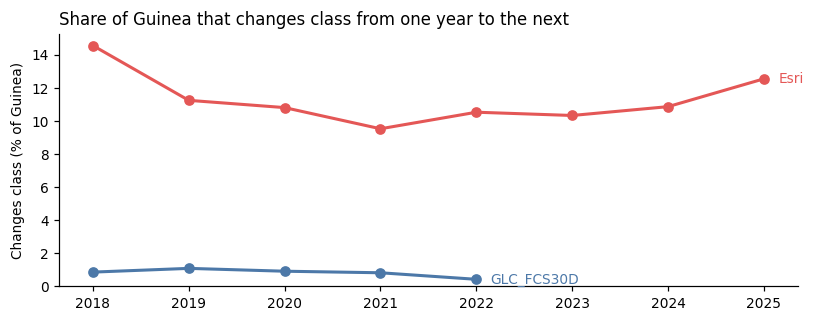

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3))
for name, colour in (("Esri", "#e45756"), ("GLC_FCS30D", "#4c78a8")):
    s = consistency[(name, "changed (% of Guinea)")].dropna()
    ax.plot(s.index, s.values, marker="o", color=colour, linewidth=2)
    ax.text(s.index[-1] + 0.15, s.values[-1], name, color=colour, va="center")
ax.set_ylabel("Changes class (% of Guinea)")
ax.set_ylim(0, None)
ax.set_title("Share of Guinea that changes class from one year to the next", loc="left")
plt.tight_layout(); plt.show()

Which changes make up Esri's yearly change, for the interval the land-use forecast learns from
(2023→2024):

In [6]:
before, now, after = (series["Esri"][y] for y in (2023, 2024, 2025))
changed = before.notna() & now.notna() & (before != now)
pairs = pd.DataFrame({"from": before[changed].map(COMMON), "to": now[changed].map(COMMON),
                      "reverts": (after[changed] == before[changed]), "km2": weights.reindex(before[changed].index)})
by_pair = pairs.groupby(["from", "to"]).agg(km2=("km2", "sum"), reverts=("reverts", "mean"))
by_pair["% of all change"] = 100 * by_pair["km2"] / by_pair["km2"].sum()
by_pair["reverts in 2025 (%)"] = 100 * by_pair.pop("reverts")
by_pair.sort_values("km2", ascending=False).head(6).round(1)

km2  % of all change  \
from              to                                            
Tree cover        Shrub & grassland  14573.8             54.7   
Shrub & grassland Tree cover          8839.1             33.2   
                  Cropland            1051.2              3.9   
Cropland          Shrub & grassland    708.1              2.7   
Built-up          Shrub & grassland    402.0              1.5   
Tree cover        Cropland             208.7              0.8   

                                     reverts in 2025 (%)  
from              to                                      
Tree cover        Shrub & grassland                 55.4  
Shrub & grassland Tree cover                        16.2  
                  Cropland                          52.9  
Cropland          Shrub & grassland                 29.6  
Built-up          Shrub & grassland                 31.1  
Tree cover        Cropland                          36.2

**Reading:**

* **Esri changes the class of 10–15 % of Guinea every year, and a third of that change (26–40 %)
  goes back the following year.** GLC_FCS30D changes about 1 % a year. Real land change in Guinea
  is far below 10 % a year: NERF's deforestation is about 0.3 % of the country a year.
* **Almost 90 % of Esri's 2023→2024 change is between tree cover and shrub & grassland**
  (rangeland), the boundary that is hardest to draw in Guinea's forest–savanna mosaic. **More than
  half of its tree cover → grassland change went back in 2025** (55 %). This is the "trend
  reversal" that the land-use forecast met when given amounts projected from 2023→2024
  (`landuse_experiments`, notebook 10).
* **For the land-use forecast** (`landuse_experiments/`), this means the "change" it is trained and
  scored on is largely Esri's year-to-year noise. Its scores rank models fairly, because every model
  faces the same noise, but they do not measure how well real land change is forecast. The flip-back
  check of `landuse_experiments` (notebook 06) exists for this reason.

### Is Dynamic World more stable?

Dynamic World is the only other 10 m product with a map every year, and it agrees slightly better
with interpreters than Esri in Guinea (77 % against 75 %, notebook 02). Its annual map here is the most
frequent label of the year at each point, as in stage 1. It is read for 2018–2025 at a lighter grid:
one point per H3 resolution-6 hexagon (about 30 km²), the centre point of each, 8,093 points. Esri is
taken at exactly the same points, so the two are compared like for like.

In [7]:
import json, time
import h3

ROOT = Path.cwd().parents[1]
DW_YEARS = list(range(2018, 2026))
light = points[points["h3_id"] == points["h3_id"].map(lambda c: h3.cell_to_center_child(h3.cell_to_parent(c, 6), 7))].copy()
light_weights = light["h3_id"].map(lambda c: h3.cell_area(h3.cell_to_parent(c, 6), unit="km^2"))   # each stands for its hexagon
DW_FILE = OUT / "01_dynamic_world_h3res6.parquet"

if DW_FILE.exists():
    dw = pd.read_parquet(DW_FILE).set_index("point_id")
else:
    import ee, geopandas as gpd
    key = next(p for p in [ROOT / "gee-account.json", *(ROOT / "Land Use-Deforestation" / "landuse_tool" / "credentials").glob("tribal*.json")]
               if p.exists())
    info = json.loads(key.read_text())
    ee.Initialize(ee.ServiceAccountCredentials(info["client_email"], str(key)), project=info["project_id"])
    bounds = gpd.read_file(ROOT / "studies" / "output_datasets" / "ecoregions_guinea.gpkg", layer="guinea_boundary").total_bounds
    collection = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1").filterBounds(ee.Geometry.Rectangle(list(bounds))).select("label")
    image = ee.Image.cat([collection.filterDate(f"{y}-01-01", f"{y + 1}-01-01").mode().rename(str(y)) for y in DW_YEARS]).unmask(-1)
    rows, started = [], time.time()
    for start in range(0, len(light), 1000):                   # 1,000 points per request, as stage 1 for Dynamic World
        chunk = light.iloc[start:start + 1000]
        fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([x, y]), {"point_id": int(i)})
                                   for i, x, y in zip(chunk.index, chunk["lon"], chunk["lat"])])
        rows += [f["properties"] for f in image.sampleRegions(collection=fc, properties=["point_id"], scale=10, tileScale=4).getInfo()["features"]]
        print(f"  {start + len(chunk):,} of {len(light):,} points, {time.time() - started:.0f} s")
    dw = pd.DataFrame(rows).set_index("point_id")
    dw.reset_index().to_parquet(DW_FILE, index=False)

DW_TO_COMMON = {0: 6, 1: 1, 2: 2, 3: 7, 4: 3, 5: 2, 6: 4, 7: 5}   # stage-1 crosswalk; 8 = snow
light_series = {"Esri": {y: series["Esri"][y].reindex(light.index) for y in DW_YEARS},
                "Dynamic World": {int(y): dw[str(y)].map(DW_TO_COMMON).reindex(light.index) for y in DW_YEARS}}


def light_year_to_year(maps):
    rows = []
    for year in sorted(maps)[1:]:
        before, now, after = maps[year - 1], maps[year], maps.get(year + 1)
        changed = before.notna() & now.notna() & (before != now)
        row = {"year": year, "changed (% of Guinea)": 100 * np.average(changed, weights=light_weights)}
        if after is not None:
            checked = changed & after.notna()
            row["reverts the next year (% of the change)"] = 100 * light_weights[checked & (after == before)].sum() / light_weights[checked].sum()
        rows.append(row)
    return pd.DataFrame(rows).set_index("year")


stability = pd.concat({name: light_year_to_year(maps) for name, maps in light_series.items()}, axis=1)
stability.loc["mean"] = stability.mean()
stability.round(2).to_csv(OUT / "01_esri_vs_dynamic_world.csv")
stability.round(2)

Esri                                          \
     changed (% of Guinea) reverts the next year (% of the change)   
year                                                                 
2019                 11.25                                   40.25   
2020                 10.82                                   29.60   
2021                  8.73                                   41.58   
2022                 10.80                                   34.14   
2023                 10.23                                   38.01   
2024                 10.58                                   40.06   
2025                 12.52                                     NaN   
mean                 10.70                                   37.27   

             Dynamic World                                          
     changed (% of Guinea) reverts the next year (% of the change)  
year                                                                
2019                 12.20                                   37.00  
2020                 11.24                                   38.98  
2021                 11.17                                   44.02  
2022                 12.26                                   43.18  
2023                 12.35                                   36.19  
2024                 11.78                                   35.28  
2025                 12.11                                     NaN  
mean                 11.87                                   39.11

In [8]:
before, now = (dw[str(y)].reindex(light.index) for y in (2023, 2024))
DW_NAMES = {0: "Water", 1: "Trees", 2: "Grass", 3: "Flooded vegetation", 4: "Crops", 5: "Shrub & scrub", 6: "Built", 7: "Bare"}
changed = before.notna() & now.notna() & (before >= 0) & (now >= 0) & (before != now)
dw_pairs = light_weights[changed].groupby([before[changed].map(DW_NAMES).rename("from"), now[changed].map(DW_NAMES).rename("to")]).sum()
print("Dynamic World's change 2023→2024, by pair of classes (% of all change):")
(100 * dw_pairs / dw_pairs.sum()).sort_values(ascending=False).head(5).round(1)

Dynamic World's change 2023→2024, by pair of classes (% of all change):


from           to           
Shrub & scrub  Trees            49.1
Trees          Shrub & scrub    34.2
Crops          Shrub & scrub     4.0
Shrub & scrub  Crops             3.9
Grass          Shrub & scrub     1.6
Name: h3_id, dtype: float64

**Reading:**

* **Dynamic World is not more stable than Esri.** At the same 8,093 points it changes the class of
  11.9 % of Guinea a year on average (Esri 10.7 %), and 39 % of that change reverts the next year
  (Esri 37 %).
* **Its change is on the same boundary:** 83 % of its 2023→2024 change is between trees and shrub
  & scrub, against 88 % between trees and rangeland for Esri. The instability comes from Guinea's
  forest–savanna mosaic, which both deep-learning products split differently from year to year,
  not from Esri alone.
* **So switching the land-use forecast to Dynamic World would not fix the noise.** Esri stays the
  practical choice: the only ready-made annual 10 m map to 2025, as accurate as Dynamic World in
  Guinea (75 % and 77 %, overlapping intervals; notebook 02).

**Two options to reduce the noise, instead of changing product** (not tested yet):

1. **Filter the annual maps over several years.** A pixel's class is changed only if the change is
   supported by the years around it, so one-year flips are removed before change is counted. This is
   how the MODIS land-cover series is made consistent, with a hidden Markov model over the years
   (Abercrombie & Friedl 2016). For the land-use forecast it would mean training and scoring on the
   filtered series; the cost is that the latest year can only be confirmed one year later.
2. **Report change between groups of classes the products can separate.** Trees and shrub /
   rangeland are merged into one "wooded and natural vegetation" group when change is counted,
   because 80–90 % of the year-to-year change of both Esri and Dynamic World is between them. Change
   into cropland, built-up, bare ground and water is kept separate. The cost is losing the trees /
   rangeland distinction in the change figures; forest change itself comes from Hansen.

## 5 · What each product can be used for

| Product | Use it for | Do not use it for | Why |
|---|---|---|---|
| **Hansen** | Where tree cover is lost, 2013 onwards; targeting hotspots | Deforestation statistics; trends across 2013 | Tree-cover loss, close to NERF's deforestation + degradation; misses small and dry-forest losses; 2013 break |
| **JRC TMF** | Deforestation vs degradation in the moist south-east; checking Hansen there | National totals | Moist forest is 3.4 % of Guinea |
| **GLC_FCS30D** | A stable annual land-cover series to 2022 | Years after 2022 | Consistent series (≈ 1 % change a year), 80.9 % overall accuracy, but not updated |
| **Esri** | Land cover of one year; the annual series, with its noise stated | Year-to-year change without filtering | 10–15 % of Guinea changes a year, a third reverts; lowest independent accuracy of the 10 m maps globally, close to Dynamic World in Guinea. No better annual alternative |
| **WorldCover** | Land cover around 2020–2021; the most accurate 10 m map | Change | Two dates, different algorithms |
| **Dynamic World** | Land cover at any date | Replacing Esri for change | As unstable as Esri (12 % of Guinea a year, 39 % reverts), on the same trees–shrub boundary |

**What tiers 2 and 3 must answer:** none of the accuracies above is for Guinea, and the official
figures give totals only. So: how accurate are Hansen, TMF and the land-cover maps *in Guinea*,
for forest and for change? Tier 2 uses public reference data that already include Guinea; tier 3,
our own sample, stratified by where the products disagree.

### References

* Abercrombie, S.P., Friedl, M.A. (2016). Improving the consistency of multitemporal land cover maps using a
  hidden Markov model. *IEEE Transactions on Geoscience and Remote Sensing* 54(2), 703–713.
* ESA (2021, 2022). *WorldCover Product Validation Reports* v1.1 and v2.0.
* Hansen, M.C., Potapov, P.V., Moore, R., et al. (2013). High-resolution global maps of 21st-century forest
  cover change. *Science* 342(6160), 850–853.
* Karra, K., Kontgis, C., Statman-Weil, Z., et al. (2021). Global land use/land cover with Sentinel 2 and deep
  learning. *IGARSS 2021*, 4704–4707.
* Masolele, R.N., Marcos, D., De Sy, V., et al. (2024). Mapping the diversity of land uses following
  deforestation across Africa. *Scientific Reports* 14, 1681.
* Olofsson, P., Foody, G.M., Herold, M., et al. (2014). Good practices for estimating area and assessing accuracy
  of land change. *Remote Sensing of Environment* 148, 42–57.
* Pontius, R.G. Jr., Lippitt, C.D. (2006). Can error explain map differences over time? *Cartography and
  Geographic Information Science* 33(2), 159–171.
* République de Guinée (2026). *Niveau de référence des forêts et niveau d'émissions de référence des forêts
  (NRF/NERF) de la Guinée*. Submitted to the UNFCCC.
* Vancutsem, C., Achard, F., Pekel, J.-F., et al. (2021). Long-term (1990–2019) monitoring of forest cover
  changes in the humid tropics. *Science Advances* 7(10), eabe1603.
* Venter, Z.S., Barton, D.N., Chakraborty, T., Simensen, T., Singh, G. (2022). Global 10 m land use land cover
  datasets: a comparison of Dynamic World, World Cover and Esri Land Cover. *Remote Sensing* 14(16), 4101.
* WRI (2024). Global Forest Review, data and methods (JRC Global Forest Cover 2020 validation by IIASA).
* Xu, P., Tsendbazar, N.-E., Herold, M., et al. (2024). Comparative validation of recent 10 m-resolution global
  land cover maps. *Remote Sensing of Environment* 311, 114316.
* Zhang, X., Zhao, T., Xu, H., et al. (2024). GLC_FCS30D: the first global 30 m land-cover dynamics monitoring
  product with a fine classification system for the period of 1985–2022. *Earth System Science Data* 16,
  1353–1381.